# Qwen3-style SLM from scratch — Smart-Home Appliance Energy

## Overview
This notebook is the course reference notebook (`5_slm_from_scratch_qwen.ipynb`, Qwen3 on TinyStories) adapted to our own collected data: question–answer pairs built from the UCI *Appliances energy prediction* dataset (one house, 10-minute readings, Jan–May 2016) by `energydata_to_sml_jsonl.ipynb`.

The pipeline is the same as the reference: Qwen3 tokenizer → `.bin` token files → Qwen3 architecture (GQA, SwiGLU, RMSNorm, RoPE) trained from random weights → loss plot → generation. No pretrained weights are used; only the tokenizer comes from `Qwen/Qwen3-8B`.

## What was changed from the reference, and why
| Change | Reason |
|---|---|
| Data: `energydata_sml_{train,val,test}.jsonl` instead of TinyStories | Our collected data. The split is chronological (train to 2016-04-20, val to 2016-05-08, test after). |
| Each example is wrapped in Qwen's chat format (a user turn, then an assistant turn closed by an end-of-turn token) | The model learns where a question ends and an answer begins, and when to stop. |
| `vocab_size = len(tokenizer)` instead of `tokenizer.vocab_size` | `tokenizer.vocab_size` (151,643) excludes the chat special tokens (ids 151,644+), which would index outside the embedding table. |
| Batches are whole examples, padded, instead of random 128-token windows | An answer is computed from the readings in its own prompt. A random window usually cuts the prompt off, which trains the model to invent numbers. |
| Loss is computed on the answer tokens only | The prompt holds sensor readings that cannot be predicted; only the answer is learnable. This also keeps the 151k-wide output layer cheap. |
| Smaller model (512 wide, 8 layers) with the embedding and output weights tied | The corpus is about 3.7M tokens, not TinyStories' ~470M. The target is a model that can run on a home energy hub. |
| Weights stay in float32; bfloat16 is used only inside autocast | The reference stores the weights in bfloat16, where small optimizer updates are rounded away. |
| Learning-rate schedule fixed (`min_lr` < `learning_rate`), fewer iterations, 4× instead of 32× gradient accumulation | In the reference `min_lr` (5e-4) is above the peak rate (1e-4). 150k iterations and an effective batch of 1,024 fit TinyStories, not 25k examples. |
| Cell order fixed, configuration moved to the top | The reference uses `block_size`, `ptdtype` and `nullcontext` before they are defined. |
| Added: evaluation on the held-out test split, and a push to the Hugging Face Hub | Required for grading; the loss alone does not show whether the answers are right. |

## Usage
1. Put `energydata_sml_train.jsonl`, `energydata_sml_val.jsonl` and `energydata_sml_test.jsonl` next to this notebook. If they are not there (for example on Colab), the same data is downloaded from the team's Hugging Face dataset `Design-Thinking-SLM/smart-home-energy-slm`.
2. Run all cells. Outputs are written to `qwen3_scratch_out/`; the best model is `qwen3_scratch_out/qwen3_slm.pt`.
3. To publish, set `PUSH_TO_HUB = True` and `HF_REPO_ID` in the last cell and run it.

# Install Required Packages

On Colab this installs the libraries. On a local machine they are expected to be in the environment already (`torch` with CUDA, `transformers`, `datasets`, `matplotlib`, `huggingface_hub`).

In [1]:
import os
import sys

# Lets PyTorch return freed GPU memory blocks instead of fragmenting them (must be set before CUDA starts).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

if "google.colab" in sys.modules:
    !pip install -q datasets transformers huggingface_hub

In [2]:
import platform
import torch

print("Python :", platform.python_version())
print("PyTorch:", torch.__version__)
print("GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

Python : 3.14.8
PyTorch: 2.11.0+cu128
GPU    : NVIDIA GeForce RTX 5060 Laptop GPU


# Configuration

All settings are in this one cell.

- **block_size**: 384 — longest example the model accepts. The longest example in the data is 355 tokens.
- **batch_size**: 8 examples per step, with gradients accumulated over 4 steps (effective batch 32). The output layer is 151,669 tokens wide, so a batch of 32 does not fit in 8 GB of GPU memory.
- **learning_rate**: 3e-4 peak, linear warm-up for 200 weight updates, then cosine decay to **min_lr** 3e-5.
- **max_iters**: 24,000 steps (6,000 weight updates), about 7.7 passes over the 25,027 training examples.
- **eval_interval**: validation loss is measured every 1,000 steps; the model with the lowest validation loss is kept.
- **Device & precision**: CUDA if available, with bfloat16 (or float16) autocast.

In [3]:
import os
import json
import math
import time
from contextlib import nullcontext

import numpy as np
import torch

# ---- data ----
DATA_DIR = "."                      # folder holding energydata_sml_{train,val,test}.jsonl
HF_DATASET_ID = "Design-Thinking-SLM/smart-home-energy-slm"   # used when the files are not in DATA_DIR
OUT_DIR = "qwen3_scratch_out"       # token files, checkpoint and evaluation results
os.makedirs(OUT_DIR, exist_ok=True)

# ---- training ----
learning_rate = 3e-4
min_lr = 3e-5
warmup_steps = 200                  # warm-up length, in weight updates
max_iters = 24000                   # training steps (batches); weight updates = max_iters / gradient_accumulation_steps
eval_interval = 1000                # evaluate every N training steps
eval_iters = 100                    # batches averaged per evaluation
batch_size = 8                      # examples per step (fits an 8 GB GPU)
block_size = 384                    # maximum sequence length (tokens)
gradient_accumulation_steps = 4     # effective batch = 8 x 4 = 32

# ---- device and precision ----
device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if "cuda" in device else "cpu"
if device_type == "cuda":
    dtype = "bfloat16" if torch.cuda.is_bf16_supported() else "float16"
else:
    dtype = "float32"
ptdtype = {"float32": torch.float32, "bfloat16": torch.bfloat16, "float16": torch.float16}[dtype]
ctx = nullcontext() if device_type == "cpu" else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

torch.manual_seed(42)
np.random.seed(42)
print(f"device={device}  autocast dtype={dtype}")

device=cuda  autocast dtype=bfloat16


# Load the Smart-Home Energy Dataset

This cell loads our collected data instead of TinyStories:

- **Source**: UCI *Appliances energy prediction* (Candanedo et al. 2017), converted to question–answer pairs by `energydata_to_sml_jsonl.ipynb`.
- **Format**: one JSON record per line with `prompt`, `completion`, `task`, `split`, `answerable`, `label`. The same data is on the Hugging Face Hub as `Design-Thinking-SLM/smart-home-energy-slm`, which is used if the local files are missing.
- **Size**: 25,027 train, 4,342 validation and 4,547 test examples across 14 task families (forecasting, window statistics, spike checks, room comparison, unit conversion, and "cannot be determined" questions).
- **Split**: chronological, so validation and test come from later weeks than training.

In [4]:
from collections import Counter
from datasets import load_dataset

data_files = {
    "train": os.path.join(DATA_DIR, "energydata_sml_train.jsonl"),
    "validation": os.path.join(DATA_DIR, "energydata_sml_val.jsonl"),
    "test": os.path.join(DATA_DIR, "energydata_sml_test.jsonl"),
}
if all(os.path.exists(p) for p in data_files.values()):
    print("loading local JSONL files from", os.path.abspath(DATA_DIR))
    ds = load_dataset("json", data_files=data_files)
    ds = ds.map(lambda e: {"task_name": e["task"]}, desc="task names")
else:
    print("local JSONL files not found; downloading", HF_DATASET_ID)
    ds = load_dataset(HF_DATASET_ID)
    task_names = ds["train"].features["task"].names        # the hub copy stores the task as a class id
    ds = ds.map(lambda e: {"task_name": task_names[e["task"]]}, desc="task names")
print(ds)

print("\nTraining examples per task:")
for task, n in Counter(ds["train"]["task_name"]).most_common():
    print(f"  {task:<16} {n}")

ex = ds["train"][0]
print("\nExample prompt:\n" + ex["prompt"])
print("\nExample completion:\n" + ex["completion"])

loading local JSONL files from /home/ojas_chaudhary/Documents/SLM Project


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

task names:   0%|          | 0/25027 [00:00<?, ? examples/s]

task names:   0%|          | 0/4342 [00:00<?, ? examples/s]

task names:   0%|          | 0/4547 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'completion', 'task', 'split', 'answerable', 'label', 'task_name'],
        num_rows: 25027
    })
    validation: Dataset({
        features: ['prompt', 'completion', 'task', 'split', 'answerable', 'label', 'task_name'],
        num_rows: 4342
    })
    test: Dataset({
        features: ['prompt', 'completion', 'task', 'split', 'answerable', 'label', 'task_name'],
        num_rows: 4547
    })
})

Training examples per task:
  forecast_next    3703
  unanswerable     2733
  window_stats     2500
  room_compare     2500
  forecast_hour    2000
  false_premise    2000
  lights_activity  1998
  spike_check      1624
  daily_profile    1299
  outdoor_weather  1295
  level_classify   1248
  units_cost       1127
  time_features    504
  noise_features   496

Example prompt:
Short-term load forecast. History (10-min steps, Wh): 
22:00  90 Wh
22:10  60 Wh
22:20  60 Wh
22:30  50 Wh
22:40  60 Wh
22:50  50 Wh. Predict the next val

# Dataset Tokenization & Preprocessing

## **What it does:**
- **Loads the Qwen3 tokenizer** (`Qwen/Qwen3-8B`, falling back to `Qwen/Qwen2.5-7B-Instruct`). Only the tokenizer is downloaded, not the 8B model.
- **Wraps each example in the Qwen chat format**:
  `<|im_start|>user\n{prompt}<|im_end|>\n<|im_start|>assistant\n{completion}<|im_end|>`
- **Creates binary files**: `train.bin`, `validation.bin` and `test.bin` (token ids as `uint32`), as in the reference.
- **Creates an index** per split (`*_idx.npy`) with each example's start position, prompt length and total length, so that a batch can be built from whole examples.

## **Notes:**
- The Qwen tokenizer splits numbers into single digits (`160` → `1`, `6`, `0`), which suits a dataset made of sensor readings.
- The vocabulary size is `len(tokenizer)`, which includes the chat special tokens.

In [5]:
from tqdm.auto import tqdm
from transformers import AutoTokenizer

# Load the Qwen3 tokenizer (tokenizer only; no model weights are downloaded)
try:
    tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
except Exception:
    tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B-Instruct")

VOCAB_SIZE = len(tokenizer)                                  # includes <|im_start|> / <|im_end|>
IM_END_ID = tokenizer.convert_tokens_to_ids("<|im_end|>")    # end of an answer
PAD_ID = tokenizer.convert_tokens_to_ids("<|endoftext|>")    # padding


def format_prompt(prompt):
    return f"<|im_start|>user\n{prompt}<|im_end|>\n<|im_start|>assistant\n"


def process(example):
    prompt_ids = tokenizer.encode(format_prompt(example["prompt"]), add_special_tokens=False)
    answer_ids = tokenizer.encode(example["completion"] + "<|im_end|>", add_special_tokens=False)
    return {"ids": prompt_ids + answer_ids, "prompt_len": len(prompt_ids), "len": len(prompt_ids) + len(answer_ids)}


tokenized = ds.map(process, remove_columns=ds["train"].column_names, desc="tokenizing the splits")

for split, dset in tokenized.items():
    rows = dset.to_list()
    lens = np.array([r["len"] for r in rows], dtype=np.int64)
    prompt_lens = np.array([r["prompt_len"] for r in rows], dtype=np.int64)
    starts = np.concatenate([[0], np.cumsum(lens)[:-1]])
    assert lens.max() <= block_size, f"{split}: an example has {lens.max()} tokens, more than block_size={block_size}"

    arr = np.memmap(os.path.join(OUT_DIR, f"{split}.bin"), dtype=np.uint32, mode="w+", shape=(int(lens.sum()),))
    for start, r in zip(tqdm(starts, desc=f"writing {split}.bin"), rows):
        arr[start:start + r["len"]] = r["ids"]
    arr.flush()
    np.save(os.path.join(OUT_DIR, f"{split}_idx.npy"), np.stack([starts, prompt_lens, lens], axis=1))

    print(f"{split:<10} {len(rows):>6} examples  {int(lens.sum()):>9,} tokens  "
          f"longest {lens.max()}  mean {lens.mean():.0f}  answer tokens {int((lens - prompt_lens).sum()):,}")

print(f"\nvocabulary size: {VOCAB_SIZE:,}")
print("number tokenisation:", tokenizer.tokenize("17:20  160 Wh"))

tokenizing the splits:   0%|          | 0/25027 [00:00<?, ? examples/s]

tokenizing the splits:   0%|          | 0/4342 [00:00<?, ? examples/s]

tokenizing the splits:   0%|          | 0/4547 [00:00<?, ? examples/s]

writing train.bin:   0%|          | 0/25027 [00:00<?, ?it/s]

train       25027 examples  3,651,729 tokens  longest 355  mean 146  answer tokens 1,172,210


writing validation.bin:   0%|          | 0/4342 [00:00<?, ?it/s]

validation   4342 examples    632,812 tokens  longest 350  mean 146  answer tokens 199,711


writing test.bin:   0%|          | 0/4547 [00:00<?, ?it/s]

test         4547 examples    657,395 tokens  longest 352  mean 145  answer tokens 210,050

vocabulary size: 151,669
number tokenisation: ['1', '7', ':', '2', '0', 'Ġ', 'Ġ', '1', '6', '0', 'ĠWh']


# Batch Data Loading Function

This function builds training batches from the tokenized files:

## **What it does:**
- **Memory mapping**: reads `*.bin` with `np.memmap`, as in the reference.
- **Whole examples**: picks `batch_size` random examples (not random token windows), so every prompt is complete.
- **Padding**: pads each batch to its longest example.
- **Answer-only targets**: the target `y` is `-100` (ignored by the loss) for prompt and padding positions, and the next token for answer positions.

## **Parameters:**
- **split**: `'train'`, `'val'` or `'test'`

## **Purpose:**
The model is trained to produce the answer given the full prompt, which is how it is used at inference.

In [6]:
SPLIT_FILE = {"train": "train", "val": "validation", "validation": "validation", "test": "test"}


def load_split(split):
    name = SPLIT_FILE[split]
    data = np.memmap(os.path.join(OUT_DIR, f"{name}.bin"), dtype=np.uint32, mode="r")
    index = np.load(os.path.join(OUT_DIR, f"{name}_idx.npy"))
    return data, index


def get_batch(split):
    data, index = load_split(split)
    ix = torch.randint(len(index), (batch_size,)).tolist()
    width = int(max(index[i, 2] for i in ix)) - 1
    x = np.full((batch_size, width), PAD_ID, dtype=np.int64)
    y = np.full((batch_size, width), -100, dtype=np.int64)
    for row, i in enumerate(ix):
        start, prompt_len, n = (int(v) for v in index[i])
        tokens = data[start:start + n].astype(np.int64)
        x[row, :n - 1] = tokens[:-1]
        y[row, prompt_len - 1:n - 1] = tokens[prompt_len:]      # answer tokens only
    x, y = torch.from_numpy(x), torch.from_numpy(y)
    if device_type == "cuda":
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y


xb, yb = get_batch("train")
print("x:", tuple(xb.shape), " y:", tuple(yb.shape), " supervised positions:", int((yb != -100).sum()))
del xb, yb

x: (8, 300)  y: (8, 300)  supervised positions: 449


# RoPE (Rotary Position Embedding) Implementation

Unchanged from the reference notebook.

## **What it does:**
- **Position encoding**: encodes positional information directly into attention queries and keys
- **Rotation-based**: uses rotation matrices, with different frequencies for different dimensions
- **Efficient**: no learnable parameters

## **Functions:**
1. **`compute_rope_params`**: pre-computes cosine and sine values for all positions
2. **`apply_rope`**: applies the rotation to attention queries and keys

In [7]:
import torch

def compute_rope_params(head_dim, theta_base=10_000, context_length=4096, dtype=torch.float32):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2, dtype=dtype)[: (head_dim // 2)].float() / head_dim))
    positions = torch.arange(context_length, dtype=dtype)
    angles = positions[:, None] * inv_freq[None, :]
    angles = torch.cat([angles, angles], dim=1)

    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

def apply_rope(x, cos, sin):
    batch_size, num_heads, seq_len, head_dim = x.shape
    assert head_dim % 2 == 0, "Head dimension must be even"

    x1 = x[..., : head_dim // 2]
    x2 = x[..., head_dim // 2 :]

    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)

    rotated = torch.cat((-x2, x1), dim=-1)
    x_rotated = (x * cos) + (rotated * sin)

    return x_rotated.to(dtype=x.dtype)

# Qwen3 Model Architecture Implementation

The building blocks are the reference notebook's: **RMSNorm**, **Grouped Query Attention** with QK normalization and RoPE, **SwiGLU** feed-forward, and pre-norm **Transformer blocks**.

## **Changes in `Qwen3Model`:**
- **Tied weights**: the output head shares the token-embedding matrix. With a 151,669-token vocabulary this table is most of the model, so sharing it removes about 78M parameters.
- **Weight initialisation**: normal with std 0.02, so the first loss is close to ln(vocab) ≈ 11.9 instead of far above it.
- **Answer-only loss**: when targets are given, the output head runs only on positions whose target is not `-100`, once and in float32. This is where the loss is defined, and it avoids building a `batch × length × 151,669` logits tensor, which is what runs an 8 GB GPU out of memory.
- **Generation**: `generate` takes `eos_id` (stop at `<|im_end|>`), and `temperature=0` gives greedy decoding, which is what a numeric answer needs.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Qwen3 RMSNorm implementation
class RMSNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(emb_dim))

    def forward(self, x):
        input_dtype = x.dtype
        x_f = x.float()
        var = x_f.pow(2).mean(dim=-1, keepdim=True)
        x_norm = x_f * torch.rsqrt(var + self.eps)
        return (x_norm * self.weight.float()).to(input_dtype)

# Qwen3 Grouped Query Attention
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_in, num_heads, num_kv_groups, head_dim=None, dtype=None):
        super().__init__()
        assert num_heads % num_kv_groups == 0, "num_heads must be divisible by num_kv_groups"

        self.num_heads = num_heads
        self.num_kv_groups = num_kv_groups
        self.group_size = num_heads // num_kv_groups

        if head_dim is None:
            head_dim = d_in // num_heads

        self.head_dim = head_dim
        self.d_out = num_heads * head_dim

        self.W_query = nn.Linear(d_in, self.d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, num_kv_groups * head_dim, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * head_dim, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(self.d_out, d_in, bias=False, dtype=dtype)

        # Qwen3 uses QK normalization
        self.q_norm = RMSNorm(head_dim, eps=1e-6)
        self.k_norm = RMSNorm(head_dim, eps=1e-6)

        self.scaling = head_dim ** -0.5

    def forward(self, x, mask, cos, sin):
        b, num_tokens, _ = x.shape

        queries = self.W_query(x)
        keys = self.W_key(x)
        values = self.W_value(x)

        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        keys = keys.view(b, num_tokens, self.num_kv_groups, self.head_dim).transpose(1, 2)
        values = values.view(b, num_tokens, self.num_kv_groups, self.head_dim).transpose(1, 2)

        # QK normalization (Qwen3 feature)
        queries = self.q_norm(queries)
        keys = self.k_norm(keys)

        # Apply RoPE
        queries = apply_rope(queries, cos, sin)
        keys = apply_rope(keys, cos, sin)

        # Expand K and V for GQA
        keys = keys.repeat_interleave(self.group_size, dim=1)
        values = values.repeat_interleave(self.group_size, dim=1)

        queries = queries * self.scaling

        # Scaled dot-product attention
        attn_scores = queries @ keys.transpose(2, 3)
        attn_scores = attn_scores.masked_fill(mask, -torch.inf)
        attn_weights = torch.softmax(attn_scores, dim=-1)

        context = (attn_weights @ values).transpose(1, 2).reshape(b, num_tokens, self.d_out)
        return self.out_proj(context)

# Qwen3 SwiGLU FeedForward
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dtype=None):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.up_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.down_proj = nn.Linear(d_ff, d_model, bias=False, dtype=dtype)

    def forward(self, x):
        # SwiGLU: Swish(gate) * up
        gate = F.silu(self.gate_proj(x))
        up = self.up_proj(x)
        return self.down_proj(gate * up)

# Qwen3 Transformer Block
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_groups, d_ff, dtype=None):
        super().__init__()
        self.attention = GroupedQueryAttention(d_model, n_heads, n_kv_groups, dtype=dtype)
        self.feed_forward = SwiGLUFeedForward(d_model, d_ff, dtype=dtype)
        self.norm1 = RMSNorm(d_model, eps=1e-6)
        self.norm2 = RMSNorm(d_model, eps=1e-6)

    def forward(self, x, mask, cos, sin):
        # Pre-norm attention
        attn_out = self.attention(self.norm1(x), mask, cos, sin)
        x = x + attn_out

        # Pre-norm feedforward
        ff_out = self.feed_forward(self.norm2(x))
        x = x + ff_out

        return x

# Qwen3 Model
class Qwen3Model(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_kv_groups, n_layers, d_ff, max_seq_len, dtype=None):
        super().__init__()

        self.tok_emb = nn.Embedding(vocab_size, d_model, dtype=dtype)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_groups, d_ff, dtype=dtype)
            for _ in range(n_layers)
        ])
        self.final_norm = RMSNorm(d_model, eps=1e-6)
        self.out_head = nn.Linear(d_model, vocab_size, bias=False, dtype=dtype)

        # RoPE parameters
        head_dim = d_model // n_heads
        cos, sin = compute_rope_params(
            head_dim=head_dim,
            context_length=max_seq_len,
            dtype=torch.float32,
        )
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

        self.d_model = d_model
        self.max_seq_len = max_seq_len

        # Small-normal initialisation, then tie the output head to the embedding table
        self.apply(self._init_weights)
        self.out_head.weight = self.tok_emb.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def _create_causal_mask(self, seq_len, device):
        return torch.triu(torch.ones((seq_len, seq_len), dtype=torch.bool, device=device), diagonal=1)

    def forward(self, input_ids, targets=None):
        b, seq_len = input_ids.shape
        x = self.tok_emb(input_ids) * (self.d_model ** 0.5)
        mask = self._create_causal_mask(seq_len, x.device)

        for block in self.blocks:
            x = block(x, mask, self.cos, self.sin)

        x = self.final_norm(x)

        if targets is None:
            return self.out_head(x), None

        # Training / evaluation: project only the supervised (answer) positions.
        # The projection is done once, in float32 and outside autocast, so only one
        # (positions x vocab) logits tensor is kept for the backward pass.
        keep = targets != -100
        with torch.autocast(device_type=x.device.type, enabled=False):
            logits = F.linear(x[keep].float(), self.out_head.weight.float())
            loss = F.cross_entropy(logits, targets[keep])
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, eos_id=None):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.max_seq_len else idx[:, -self.max_seq_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :].float()
            if temperature == 0:
                idx_next = logits.argmax(dim=-1, keepdim=True)          # greedy
            else:
                logits = logits / temperature
                if top_k is not None:
                    v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                    logits[logits < v[:, [-1]]] = float("-inf")
                probs = F.softmax(logits, dim=-1)
                idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
            if eos_id is not None and (idx_next == eos_id).all():
                break
        return idx

# Model Evaluation Function

Estimates the loss on the training and validation splits:

- **Loss estimation**: averages the loss over `eval_iters` random batches per split
- **Model state management**: switches to eval mode, then back to train mode
- **No gradients**: uses `torch.no_grad()`

The loss is the cross-entropy on answer tokens only, so it is not comparable with the TinyStories loss in the reference notebook.

In [9]:
def estimate_loss(model, eval_iters=eval_iters):
    out = {}
    model.eval()
    with torch.no_grad():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y = get_batch(split)
                with ctx:
                    logits, loss = model(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean().item()
    model.train()
    return out

# Model Configuration & Initialization

## **Configuration Parameters:**
- **vocab_size**: `len(tokenizer)` = 151,669
- **d_model**: 512 — embedding dimension
- **n_heads**: 8 — attention heads
- **n_kv_groups**: 4 — key-value groups for Grouped Query Attention
- **n_layers**: 8 — transformer layers
- **d_ff**: 2048 — feed-forward dimension (4 × d_model)
- **max_seq_len**: `block_size` (384)

## **Size:**
About 109M parameters: 78M in the token-embedding table (shared with the output head) and 31M in the transformer blocks. The reference model has about 283M.

In [10]:
QWEN3_CONFIG = {
    'vocab_size': VOCAB_SIZE,      # len(tokenizer), includes the chat special tokens
    'd_model': 512,
    'n_heads': 8,
    'n_kv_groups': 4,              # must divide n_heads
    'n_layers': 8,
    'd_ff': 2048,                  # 4 * d_model
    'max_seq_len': block_size,
}
torch.manual_seed(123)
model = Qwen3Model(**QWEN3_CONFIG).to(device)

n_params = sum(p.numel() for p in model.parameters())
n_emb = model.tok_emb.weight.numel()
print(f"parameters: {n_params/1e6:.1f}M  (embedding table {n_emb/1e6:.1f}M, transformer blocks {(n_params - n_emb)/1e6:.1f}M)")

parameters: 109.1M  (embedding table 77.7M, transformer blocks 31.5M)


# Optimizer & Scheduler

- **AdamW optimizer** with weight decay 0.1 on the weight matrices (not on the RMSNorm gains)
- **Learning-rate schedule**: linear warm-up, then cosine decay from `learning_rate` down to `min_lr`, stepped once per weight update
- **Gradient scaling**: only active when the autocast dtype is float16

In [11]:
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

decay_params = [p for p in model.parameters() if p.dim() >= 2]
no_decay_params = [p for p in model.parameters() if p.dim() < 2]
optimizer = torch.optim.AdamW(
    [{"params": decay_params, "weight_decay": 0.1}, {"params": no_decay_params, "weight_decay": 0.0}],
    lr=learning_rate, betas=(0.9, 0.95), eps=1e-8,
)

# The schedule is counted in weight updates (one per gradient_accumulation_steps batches).
total_updates = math.ceil(max_iters / gradient_accumulation_steps)
scheduler_warmup = LinearLR(optimizer, start_factor=0.05, total_iters=warmup_steps)
scheduler_decay = CosineAnnealingLR(optimizer, T_max=max(1, total_updates - warmup_steps), eta_min=min_lr)
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps])

scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

# Model Training Loop

## **Training Process:**
- **Iterative training**: `max_iters` steps of `batch_size` examples
- **Periodic evaluation**: every `eval_interval` steps on the train and validation splits
- **Best model saving**: the weights with the lowest validation loss are saved to `qwen3_scratch_out/qwen3_slm.pt`
- **Mixed precision** and **gradient clipping** (max norm 1.0)

## **Output:**
- Loss values and learning rate at each evaluation
- `train_loss_list` and `validation_loss_list` for the plot below

In [12]:
best_val_loss = float('inf')
best_iter = -1
best_model_params_path = os.path.join(OUT_DIR, "qwen3_slm.pt")
train_loss_list, validation_loss_list, eval_steps = [], [], []

model.train()
optimizer.zero_grad(set_to_none=True)
t0 = time.time()

for it in tqdm(range(max_iters), mininterval=30):
    if it % eval_interval == 0 or it == max_iters - 1:
        losses = estimate_loss(model)
        print(f"step {it:>5}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}, "
              f"lr {optimizer.param_groups[0]['lr']:.6f}, {time.time() - t0:.0f}s")
        eval_steps.append(it)
        train_loss_list.append(losses['train'])
        validation_loss_list.append(losses['val'])

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            best_iter = it
            torch.save(model.state_dict(), best_model_params_path)

    X, y = get_batch("train")

    with ctx:
        logits, loss = model(X, y)
        loss = loss / gradient_accumulation_steps
    scaler.scale(loss).backward()

    if ((it + 1) % gradient_accumulation_steps == 0) or (it + 1 == max_iters):
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()

train_minutes = (time.time() - t0) / 60
print(f"\ntraining time: {train_minutes:.1f} min")
if device_type == "cuda":
    print(f"peak GPU memory used by PyTorch: {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")
print(f"best validation loss {best_val_loss:.4f} at step {best_iter}; saved to {best_model_params_path}")

  0%|          | 0/24000 [00:00<?, ?it/s]

step     0: train loss 11.9898, val loss 11.9908, lr 0.000015, 9s


step  1000: train loss 0.2396, val loss 0.2639, lr 0.000300, 88s


step  2000: train loss 0.1526, val loss 0.1550, lr 0.000298, 172s


step  3000: train loss 0.1138, val loss 0.1212, lr 0.000294, 255s


step  4000: train loss 0.0939, val loss 0.1071, lr 0.000288, 337s


... (16 outputs left out)

step 21000: train loss 0.0367, val loss 0.0655, lr 0.000041, 1686s


step 22000: train loss 0.0314, val loss 0.0680, lr 0.000035, 1764s


step 23000: train loss 0.0277, val loss 0.0657, lr 0.000031, 1841s


step 23999: train loss 0.0254, val loss 0.0677, lr 0.000030, 1918s

training time: 32.0 min
peak GPU memory used by PyTorch: 4.1 GiB
best validation loss 0.0574 at step 20000; saved to qwen3_scratch_out/qwen3_slm.pt


# Training Loss Visualization

Training loss (green) and validation loss (red), measured every `eval_interval` steps. The y-axis is logarithmic because the loss falls by two orders of magnitude.

- **Both curves falling**: the model is learning
- **Validation rising while training falls**: overfitting; the saved model is the one at the validation minimum

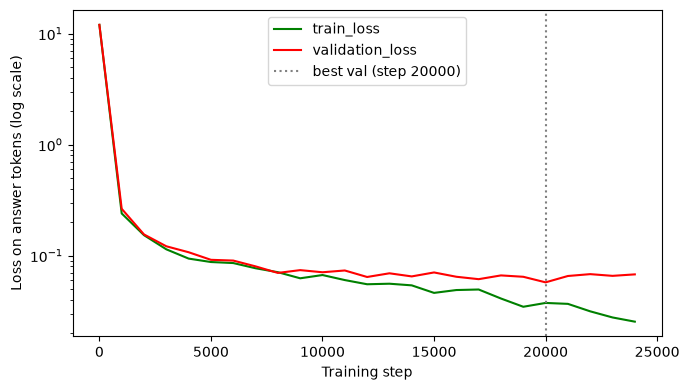

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(eval_steps, train_loss_list, 'g', label='train_loss')
plt.plot(eval_steps, validation_loss_list, 'r', label='validation_loss')
plt.axvline(best_iter, color='gray', linestyle=':', label=f'best val (step {best_iter})')
plt.yscale('log')
plt.xlabel("Training step")
plt.ylabel("Loss on answer tokens (log scale)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150)
plt.show()

# Load Best Model & Generate Answers

- **Model loading**: a fresh model with the same configuration, loaded from the best checkpoint
- **`answer(prompt)`**: wraps the question in the chat format, generates greedily until `<|im_end|>`, and returns the decoded answer
- **Demonstration**: one question per task family from the held-out **test** split (dates after 2016-05-08, never seen in training), shown with the reference answer

In [14]:
# Load the best model
model = Qwen3Model(**QWEN3_CONFIG)
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device)))
model = model.to(device).eval()


def answer(prompt, max_new_tokens=128):
    context = torch.tensor(tokenizer.encode(format_prompt(prompt), add_special_tokens=False)).unsqueeze(0).to(device)
    with ctx:
        y = model.generate(context, max_new_tokens, temperature=0, eos_id=IM_END_ID)
    new_tokens = y[0, context.size(1):].tolist()
    if IM_END_ID in new_tokens:
        new_tokens = new_tokens[:new_tokens.index(IM_END_ID)]
    return tokenizer.decode(new_tokens).strip()


shown = set()
for ex in ds["test"]:
    if ex["task_name"] in shown:
        continue
    shown.add(ex["task_name"])
    print(f"[{ex['task_name']}]")
    print("Q:", ex["prompt"])
    print("Model    :", answer(ex["prompt"]))
    print("Reference:", ex["completion"])
    print()

[forecast_next]
Q: Given these 3 consecutive 10-minute appliance readings: 
09:00  50 Wh
09:10  50 Wh
09:20  50 Wh
What is the expected energy use in the following 10 minutes?


Model    : The next 10-minute reading is expected to be about 40 Wh, a low level for this house. This is a point forecast from the recent readings and it carries uncertainty: appliance load in this dataset is spiky and right-skewed (median ≈ 60 Wh).
Reference: The next 10-minute reading is expected to be about 50 Wh, a low level for this house. This is a point forecast from the recent readings and it carries uncertainty: appliance load in this dataset is spiky and right-skewed (median ≈ 60 Wh).

[forecast_hour]
Q: Using the previous 12 readings 60, 60, 60, 70, 100, 40, 50, 50, 80, 50, 180, 90 (Wh, oldest first, 10-minute intervals), forecast the energy the appliances will use over the coming 60 minutes.


Model    : The next hour is expected to total about 510 Wh (0.51 kWh), which is the sum of six 10-minute intervals with an average of 85 Wh each. Treat this as an estimate; individual intervals can spike well above the average.
Reference: The next hour is expected to total about 900 Wh (0.90 kWh), which is the sum of six 10-minute intervals with an average of 150 Wh each. Treat this as an estimate; individual intervals can spike well above the average.

[window_stats]
Q: Appliance energy readings from 2016-05-12 17:20 to 2016-05-12 17:50 (10-minute intervals): 120, 110, 470, 340 (Wh, oldest first, 10-minute intervals).
What is the total energy used?
Model    : The total is 950 Wh (0.950 kWh) across 4 readings.
Reference: The total is 1040 Wh (1.040 kWh) across 4 readings.

[daily_profile]
Q: Hourly appliance energy (Wh) for Tuesday 2016-05-24: 00h=300, 01h=340, 02h=330, 03h=320, 04h=320, 05h=640, 06h=430, 07h=970, 08h=340, 09h=230, 10h=400, 11h=610, 12h=770, 13h=710, 14h=900, 15h=850, 

Model    : Between 00:00 and 06:00 the appliances used 1650 Wh, which is 16% of the daily 10340 Wh.
Reference: Between 00:00 and 06:00 the appliances used 2250 Wh, which is 16% of the daily 13850 Wh.

[level_classify]
Q: Appliances: 50 Wh at 2016-05-17 09:00. Is that unusually high?


Model    : No. 50 Wh is low: it is below the 90th percentile (210 Wh). These bands are percentiles of the training period. For this house, readings up to 60 Wh are low (at or below the median), up to 210 Wh moderate, up to 340 Wh high, and 340 Wh or more is peak (top 5%).
Reference: No. 50 Wh is low: it is below the 90th percentile (210 Wh). These bands are percentiles of the training period. For this house, readings up to 60 Wh are low (at or below the median), up to 210 Wh moderate, up to 340 Wh high, and 340 Wh or more is peak (top 5%).

[spike_check]
Q: Check this reading for an anomaly. Recent history: 90, 100, 100, 110, 130, 110, 110, 300, 360, 140, 100, 200 (Wh, oldest first, 10-minute intervals). Current: 330 Wh at 2016-05-15 17:40.


Model    : Yes, flag it. The recent median is 110 Wh with a robust spread (1.4826 × MAD) of 15 Wh, so the new reading is +18.9 robust standard deviations from typical. It also exceeds the house's 90th percentile (210 Wh). The data only shows total appliance energy, so it cannot tell which appliance caused the spike or whether it indicates a fault.
Reference: Yes, flag it. The recent median is 110 Wh with a robust spread (1.4826 × MAD) of 22 Wh, so the new reading is +9.9 robust standard deviations from typical. It also exceeds the house's 90th percentile (210 Wh). The data only shows total appliance energy, so it cannot tell which appliance caused the spike or whether it indicates a fault.

[room_compare]
Q: Snapshot: RH_3=37.0 %, RH_7=35.8 %, RH_2=36.0 %
How much higher is the humidity in the living room than in the laundry room?


... (3 outputs left out)

Model    : That cannot be calculated from the data: the dataset contains no electricity tariff or price. Give a price per kWh and multiply it by 0.080 kWh to get the cost.
Reference: That cannot be calculated from the data: the dataset contains no electricity tariff or price. Give a price per kWh and multiply it by 0.080 kWh to get the cost.

[noise_features]
Q: rv1 is 32.35 and rv2 is 32.35. How do these values affect appliance energy use?


Model    : They have no effect. rv1 and rv2 are random variables that the dataset authors added on purpose to test feature selection. They carry no information about consumption (rv2 is an exact copy of rv1), so they should be excluded from a model and never used to explain a reading.
Reference: They have no effect. rv1 and rv2 are random variables that the dataset authors added on purpose to test feature selection. They carry no information about consumption (rv2 is an exact copy of rv1), so they should be excluded from a model and never used to explain a reading.

[unanswerable]
Q: What was the appliances energy consumption on 2017-03-18 at 18:00 according to the dataset?


Model    : That date is outside the dataset. The dataset covers 2016-01-11 17:00 to 2016-05-27 18:00 at 10-minute resolution, so there is no recorded value for 2017-03-18.
Reference: That date is outside the dataset. The dataset covers 2016-01-11 17:00 to 2016-05-27 18:00 at 10-minute resolution, so there is no recorded value for 2017-03-18.

[false_premise]
Q: In this hour 
17:30  100 Wh
17:40  490 Wh
17:50  570 Wh
18:00  460 Wh
18:10  120 Wh
18:20  100 Wh the appliances peaked at 1110 Wh. What caused it?


Model    : The premise is incorrect. None of these readings reaches 1110 Wh; the highest is 490 Wh (peak for this house). There is no 1110 Wh jump to explain.
Reference: The premise is incorrect. None of these readings reaches 1110 Wh; the highest is 570 Wh (peak for this house). There is no 1110 Wh jump to explain.



# Evaluation on the Held-Out Test Split

The reference notebook stops at one generated sample. Here the model answers `EVAL_PER_TASK` test questions from each task family and is scored against the reference answers:

- **Exact match**: the generated answer equals the reference text. The references are built from templates and computed from the numbers in the prompt, so an exact match means both the wording and every number are right.
- **Numbers match**: the numbers in the generated answer equal the numbers in the reference, in order, whatever the wording.

Results are saved to `qwen3_scratch_out/test_eval.json`.

In [15]:
import random
import re

EVAL_PER_TASK = 25
NUM_RE = re.compile(r"-?\d+(?:\.\d+)?")

by_task = {}
for ex in ds["test"]:
    by_task.setdefault(ex["task_name"], []).append(ex)

rng = random.Random(0)
samples = {task: rng.sample(by_task[task], min(EVAL_PER_TASK, len(by_task[task]))) for task in sorted(by_task)}
progress = tqdm(total=sum(len(v) for v in samples.values()), desc="answering test questions", mininterval=30)
results = {}
mismatches = []
for task, sample in samples.items():
    exact = numbers = 0
    for ex in sample:
        out = answer(ex["prompt"])
        progress.update(1)
        ref = ex["completion"].strip()
        exact += out == ref
        numbers += NUM_RE.findall(out) == NUM_RE.findall(ref)
        if out != ref and len(mismatches) < 200:
            mismatches.append({"task": task, "prompt": ex["prompt"], "model": out, "reference": ref})
    results[task] = {"n": len(sample), "exact_match": exact / len(sample), "numbers_match": numbers / len(sample)}

progress.close()

total = sum(r["n"] for r in results.values())
overall = {
    "n": total,
    "exact_match": sum(r["exact_match"] * r["n"] for r in results.values()) / total,
    "numbers_match": sum(r["numbers_match"] * r["n"] for r in results.values()) / total,
}

print(f"{'task':<18}{'n':>4}{'exact match':>14}{'numbers match':>16}")
for task, r in results.items():
    print(f"{task:<18}{r['n']:>4}{r['exact_match']:>13.0%}{r['numbers_match']:>15.0%}")
print(f"{'ALL':<18}{overall['n']:>4}{overall['exact_match']:>13.0%}{overall['numbers_match']:>15.0%}")

with open(os.path.join(OUT_DIR, "test_eval.json"), "w") as f:
    json.dump({"overall": overall, "per_task": results, "mismatches": mismatches}, f, indent=2, ensure_ascii=False)

print("\nExamples the model got wrong:")
seen_tasks = set()
for m in mismatches:
    if m["task"] in seen_tasks or len(seen_tasks) >= 3:
        continue
    seen_tasks.add(m["task"])
    print(f"\n[{m['task']}]\nQ: {m['prompt']}\nModel    : {m['model']}\nReference: {m['reference']}")

answering test questions:   0%|          | 0/350 [00:00<?, ?it/s]

task                 n   exact match   numbers match
daily_profile       25           0%             0%
false_premise       25         100%           100%
forecast_hour       25          12%            12%
forecast_next       25           4%             4%
level_classify      25         100%           100%
lights_activity     25         100%           100%
noise_features      25         100%           100%
outdoor_weather     25          36%            36%
room_compare        25          40%            40%
spike_check         25           8%             8%
time_features       25          52%            76%
unanswerable        25         100%           100%
units_cost          25          88%            88%
window_stats        25          16%            16%
ALL                350          54%            56%

Examples the model got wrong:

[daily_profile]
Q: Hourly appliance energy (Wh) for Monday 2016-05-16: 00h=370, 01h=320, 02h=340, 03h=320, 04h=330, 05h=310, 06h=320, 07h=370, 08h=530

# Push the Trained Model to the Hugging Face Hub

Uploads the trained model for demonstration and grading:

- `qwen3_slm.pt` — the trained weights (state dict)
- `config.json` — the model configuration and training settings
- tokenizer files — so the repository is self-contained
- `test_eval.json`, `loss_curve.png`
- `README.md` — a model card with the test results
- this notebook, which holds the model code needed to load the weights

Set `PUSH_TO_HUB = True` and check `HF_REPO_ID`, then run the cell. It creates a new model repository and does not touch the existing LoRA model `Design-Thinking-SLM/smart-home-energy-slm`. You need to be logged in (`huggingface-cli login`, or `from huggingface_hub import login; login()` on Colab) with a token that has write access.

In [16]:
PUSH_TO_HUB = False
HF_REPO_ID = "Design-Thinking-SLM/smart-home-energy-qwen3-scratch"   # the team org; change to your own account if needed
NOTEBOOK_PATH = "5_slm_from_scratch_qwen.ipynb"

import shutil

export_dir = os.path.join(OUT_DIR, "hf_export")
os.makedirs(export_dir, exist_ok=True)

shutil.copy(best_model_params_path, os.path.join(export_dir, "qwen3_slm.pt"))
for name in ("test_eval.json", "loss_curve.png"):
    shutil.copy(os.path.join(OUT_DIR, name), os.path.join(export_dir, name))
if os.path.exists(NOTEBOOK_PATH):
    shutil.copy(NOTEBOOK_PATH, os.path.join(export_dir, os.path.basename(NOTEBOOK_PATH)))
tokenizer.save_pretrained(export_dir)

with open(os.path.join(export_dir, "config.json"), "w") as f:
    json.dump({
        "architecture": "Qwen3-style decoder (GQA, SwiGLU, RMSNorm, RoPE), trained from scratch",
        "model_config": QWEN3_CONFIG,
        "tied_embeddings": True,
        "parameters": n_params,
        "tokenizer": tokenizer.name_or_path,
        "prompt_format": "<|im_start|>user\n{prompt}<|im_end|>\n<|im_start|>assistant\n",
        "training": {
            "max_iters": max_iters, "batch_size": batch_size, "gradient_accumulation_steps": gradient_accumulation_steps,
            "block_size": block_size,
            "learning_rate": learning_rate, "min_lr": min_lr, "warmup_steps": warmup_steps,
            "best_val_loss": best_val_loss, "best_iter": best_iter,
        },
    }, f, indent=2)

rows = "\n".join(
    f"| {task} | {r['n']} | {r['exact_match']:.0%} | {r['numbers_match']:.0%} |" for task, r in results.items()
)
model_card = f'''---
language: en
license: cc-by-4.0
tags: [energy, smart-home, forecasting, slm, qwen3, from-scratch]
pipeline_tag: text-generation
---

# Smart-Home Appliance Energy SLM (Qwen3 architecture, trained from scratch)

A {n_params/1e6:.0f}M-parameter small language model with the Qwen3 architecture (Grouped Query Attention,
SwiGLU, RMSNorm, RoPE), trained from random weights on question-answer pairs built from the UCI
"Appliances energy prediction" dataset (Candanedo et al. 2017; one house, 10-minute readings, Jan-May 2016).
It uses the `{tokenizer.name_or_path}` tokenizer. No pretrained weights are used.

It answers short questions about appliance energy readings: next-step and next-hour forecasts, window
statistics, spike checks, room comparisons, unit and cost conversion, and it says "cannot be determined"
for questions the data cannot answer (occupancy, per-appliance use, faults, tariffs).

## Results on the held-out test split (dates after 2016-05-08)

Greedy decoding, {overall['n']} questions. "Exact match" compares the full answer with the reference;
"numbers match" compares only the numbers.

| Task | n | Exact match | Numbers match |
|---|---|---|---|
{rows}
| **All** | {overall['n']} | {overall['exact_match']:.0%} | {overall['numbers_match']:.0%} |

Best validation loss (answer tokens): {best_val_loss:.4f} at step {best_iter} of {max_iters}.

## Use

The weights are a PyTorch state dict (`qwen3_slm.pt`). The model class `Qwen3Model` is defined in the
notebook in this repository; `config.json` holds its arguments under `model_config`. Prompt format:

```
<|im_start|>user
{{question}}<|im_end|>
<|im_start|>assistant
```

## Limitations

Trained on one house over winter and spring only. It is a course project, not a tool for billing or safety decisions.
'''
with open(os.path.join(export_dir, "README.md"), "w") as f:
    f.write(model_card)

print("export folder:", export_dir)
for name in sorted(os.listdir(export_dir)):
    print(f"  {name:<28} {os.path.getsize(os.path.join(export_dir, name))/1e6:8.2f} MB")

if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    api = HfApi()
    api.create_repo(HF_REPO_ID, repo_type="model", exist_ok=True)
    api.upload_folder(folder_path=export_dir, repo_id=HF_REPO_ID, repo_type="model")
    print(f"pushed to https://huggingface.co/{HF_REPO_ID}")
else:
    print("\nPUSH_TO_HUB is False: nothing was uploaded.")

export folder: qwen3_scratch_out/hf_export
  5_slm_from_scratch_qwen.ipynb     0.05 MB
  README.md                        0.00 MB
  chat_template.jinja              0.00 MB
  config.json                      0.00 MB
  loss_curve.png                   0.05 MB
  qwen3_slm.pt                   436.52 MB
  test_eval.json                   0.10 MB
  tokenizer.json                  11.42 MB
  tokenizer_config.json            0.00 MB

PUSH_TO_HUB is False: nothing was uploaded.
